# 02 — Page inspection features

## Objective

Measure native word count, raster image count, and largest image coverage for representative PDF pages. These features will support—but not prove—the extraction route chosen in the next notebook.

## Concept

For an image with bounding box $B$ and page rectangle $P$, its visible page coverage is

$$
\text{coverage}=\frac{\operatorname{area}(B\cap P)}{\operatorname{area}(P)}.
$$

The intersection prevents off-page image geometry from producing coverage above 1. A page-sized image plus very few native words is evidence of a scan, but thresholds remain heuristics.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import pymupdf

plt.style.use("seaborn-v0_8-whitegrid")


def find_project_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Could not find the repository root")


PROJECT_ROOT = find_project_root()
DOCUMENTS_DIR = PROJECT_ROOT / "data" / "documents"

## Implementation — calculate one page by hand

We first keep each intermediate value visible before wrapping the operation in a function.

In [2]:
with pymupdf.open(DOCUMENTS_DIR / "scanned.pdf") as document:
    example_page = document[0]
    example_words = example_page.get_text("words")
    example_images = example_page.get_image_info()
    example_page_area = example_page.rect.get_area()
    example_image_areas = [
        (pymupdf.Rect(image["bbox"]) & example_page.rect).get_area()
        for image in example_images
    ]

example_features = {
    "native_words": len(example_words),
    "image_count": len(example_images),
    "largest_image_fraction": round(max(example_image_areas, default=0) / example_page_area, 3),
}
example_features

{'native_words': 2, 'image_count': 1, 'largest_image_fraction': 1.0}

## Implementation — package the repeated operation

`inspect_page` accepts one open PyMuPDF page and returns only observed features. It does not decide whether OCR is correct.

In [3]:
def inspect_page(page):
    words = page.get_text("words")
    images = page.get_image_info()
    page_area = page.rect.get_area()
    largest_coverage = max(
        (
            (pymupdf.Rect(image["bbox"]) & page.rect).get_area() / page_area
            for image in images
        ),
        default=0.0,
    )
    return {
        "native_words": len(words),
        "image_count": len(images),
        "largest_image_fraction": round(largest_coverage, 3),
    }

## Execution — compare representative pages

In [4]:
samples = {
    "ch2.pdf": [9, 17, 49, 65],
    "scanned.pdf": [1, 2, 3],
}

feature_rows = []
for filename, page_numbers in samples.items():
    with pymupdf.open(DOCUMENTS_DIR / filename) as document:
        for page_number in page_numbers:
            feature_rows.append(
                {
                    "page_id": f"{filename} p.{page_number}",
                    "filename": filename,
                    "page_number": page_number,
                    **inspect_page(document[page_number - 1]),
                }
            )

page_features = pd.DataFrame(feature_rows)
page_features

,page_id,filename,page_number,native_words,image_count,largest_image_fraction
0,ch2.pdf p.9,ch2.pdf,9,148,0,0.000
1,ch2.pdf p.17,ch2.pdf,17,167,0,0.000
2,ch2.pdf p.49,ch2.pdf,49,216,0,0.000
3,ch2.pdf p.65,ch2.pdf,65,39,2,0.807
4,scanned.pdf p.1,scanned.pdf,1,2,1,1.000
5,scanned.pdf p.2,scanned.pdf,2,0,1,1.000
6,scanned.pdf p.3,scanned.pdf,3,0,1,1.000


## Inspection — words and image coverage use separate axes

The two measurements have different units, so separate panels avoid a misleading shared scale.

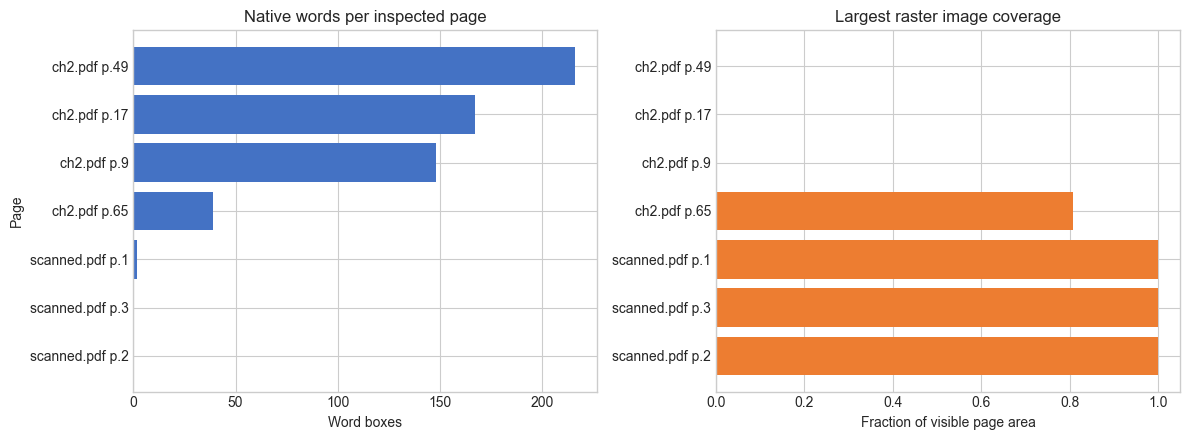

In [5]:
plot_data = page_features.sort_values("native_words")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].barh(plot_data["page_id"], plot_data["native_words"], color="#4472C4")
axes[0].set_title("Native words per inspected page")
axes[0].set_xlabel("Word boxes")
axes[0].set_ylabel("Page")

axes[1].barh(plot_data["page_id"], plot_data["largest_image_fraction"], color="#ED7D31")
axes[1].set_title("Largest raster image coverage")
axes[1].set_xlabel("Fraction of visible page area")
axes[1].set_xlim(0, 1.05)
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

## Interpretation

The scanned pages are characterized by near-page-sized raster images and few or no native words. The selected slide pages contain many native words, but page 65 demonstrates why a single coverage threshold cannot guarantee that text inside a figure is recovered.

## Validation

In [6]:
with pymupdf.open(DOCUMENTS_DIR / "scanned.pdf") as document:
    function_features = inspect_page(document[0])

assert example_features == function_features, "The function should reproduce the transparent calculation"
assert page_features["largest_image_fraction"].between(0, 1).all()
assert (page_features["native_words"] >= 0).all()
assert len(page_features) == sum(len(pages) for pages in samples.values())

print("Feature ranges and sample coverage are valid.")

Feature ranges and sample coverage are valid.


## Next step

`03_extraction_routing.ipynb` makes the heuristic decision boundaries explicit and tests both known pages and synthetic edge cases.